In [15]:
from google.colab import drive, userdata
import os, sys
drive.mount('/content/drive')

TOKEN = userdata.get('GITHUB_TOKEN')
USER, REPO = "jeevithrao", "ML_AL_MC"
REPO_DIR = f"/content/{REPO}"
if not os.path.exists(REPO_DIR):
    !git clone https://{TOKEN}@github.com/{USER}/{REPO}.git {REPO_DIR}
%cd {REPO_DIR}
!git remote set-url origin https://{TOKEN}@github.com/{USER}/{REPO}.git
!git config user.name "jeevithrao"
!git config user.email "138958136+jeevithrao@users.noreply.github.com"
!git pull origin main
sys.path.append(f"{REPO_DIR}/src")
os.environ["PYTHONPATH"] = f"{REPO_DIR}/src"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/ML_AL_MC
From https://github.com/jeevithrao/ML_AL_MC
 * branch            main       -> FETCH_HEAD
Already up to date.


In [16]:
import os
p = "/content/drive/MyDrive/birdclef_project"
print("folder exists:", os.path.exists(p))
print(os.listdir(p) if os.path.exists(p) else "missing")
print("ML_AL_MC results:", sorted(os.listdir("/content/ML_AL_MC/results")))

folder exists: True
['train_metadata.csv', 'mels.tar']
ML_AL_MC results: ['.gitkeep', 'chunk_index.csv', 'classes.json', 'failed_files.csv', 'file_splits.csv']


In [17]:
need = ["results/chunk_index.csv", "results/classes.json", "results/file_splits.csv"]
for p in need:
    print(p, "->", os.path.exists(p))
TAR = "/content/drive/MyDrive/birdclef_project/mels.tar"
print(TAR, "->", os.path.exists(TAR))

results/chunk_index.csv -> True
results/classes.json -> True
results/file_splits.csv -> True
/content/drive/MyDrive/birdclef_project/mels.tar -> True


In [18]:
!pip install -q timm scikit-learn
!mkdir -p /content/data
!tar -xf {TAR} -C /content/data
!ls /content/data/mels | wc -l

24459


In [19]:
%%writefile src/train_config.py
SEED = 42
N_CLASSES = 182
BACKBONE = "efficientnet_b0"
BATCH = 64
EPOCHS = 10
LR = 1e-3
WD = 1e-2
PCT_START = 0.1
NUM_WORKERS = 2
MIXUP_P = 0.5
MIXUP_LAM = (0.3, 0.7)
SPEC_MASKS = 2
FREQ_MASK = 16
TIME_MASK = 40

Overwriting src/train_config.py


In [20]:
%%writefile src/data_utils.py
import ast, numpy as np, torch
from torch.utils.data import Dataset

def build_targets(idx, classes):
    cid = {c: i for i, c in enumerate(classes)}
    Y = np.zeros((len(idx), len(classes)), dtype=np.float32)
    for r, (p, s) in enumerate(zip(idx.primary_label, idx.secondary_labels)):
        Y[r, cid[p]] = 1.0
        if isinstance(s, str):
            for c in ast.literal_eval(s):
                if c in cid:
                    Y[r, cid[c]] = 1.0
    return Y

def sqrt_inv_weights(labels):
    import pandas as pd
    s = pd.Series(labels)
    cnt = s.map(s.value_counts()).values
    return (1.0 / np.sqrt(cnt)).astype(np.float64)

class MelDataset(Dataset):
    def __init__(self, path, rows, Y):
        self.path, self.rows, self.Y = path, np.asarray(rows), Y
        self.mm = None
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, i):
        if self.mm is None:                      # opened lazily, once per worker
            self.mm = np.load(self.path, mmap_mode="r")
        r = self.rows[i]
        x = torch.from_numpy(np.array(self.mm[r], dtype=np.float32))
        return x, torch.from_numpy(self.Y[r]), int(r)

Overwriting src/data_utils.py


In [21]:
%%writefile src/model.py
import timm

def make_model(name="efficientnet_b0", n_classes=182, pretrained=True):
    return timm.create_model(name, pretrained=pretrained, in_chans=1,
                             num_classes=n_classes, drop_rate=0.3, drop_path_rate=0.1)

Overwriting src/model.py


In [22]:
%%writefile src/metrics.py
import numpy as np
from sklearn.metrics import roc_auc_score

def per_class_auc(Y, P):
    out = np.full(Y.shape[1], np.nan)
    for c in range(Y.shape[1]):
        pos = Y[:, c].sum()
        if 0 < pos < len(Y):
            out[c] = roc_auc_score(Y[:, c], P[:, c])
    return out

def macro_auc(Y, P):
    a = per_class_auc(Y, P)
    return float(np.nanmean(a)), int(np.sum(~np.isnan(a)))

Overwriting src/metrics.py


In [23]:
%%writefile src/engine.py
import os, time, numpy as np, torch, torch.nn as nn
from torch.utils.data import DataLoader, WeightedRandomSampler
from train_config import *
from metrics import macro_auc

DEV = "cuda"

def prep(x):
    # chunks are in [-80, 0] dB; map to roughly [-1, 1]
    return ((x + 40.0) / 40.0).unsqueeze(1)

def time_shift(x):
    return torch.roll(x, shifts=int(np.random.randint(0, x.size(-1))), dims=-1)

def spec_augment(x):
    B, _, F, T = x.shape
    fa = torch.arange(F, device=x.device).view(1, 1, F, 1)
    ta = torch.arange(T, device=x.device).view(1, 1, 1, T)
    fill = x.mean(dim=(1, 2, 3), keepdim=True)
    for _ in range(SPEC_MASKS):
        fw = torch.randint(0, FREQ_MASK + 1, (B, 1, 1, 1), device=x.device)
        f0 = (torch.rand(B, 1, 1, 1, device=x.device) * (F - fw)).long()
        tw = torch.randint(0, TIME_MASK + 1, (B, 1, 1, 1), device=x.device)
        t0 = (torch.rand(B, 1, 1, 1, device=x.device) * (T - tw)).long()
        m = ((fa >= f0) & (fa < f0 + fw)) | ((ta >= t0) & (ta < t0 + tw))
        x = torch.where(m, fill.expand_as(x), x)
    return x

def mixup(x, y):
    lam = float(np.random.uniform(*MIXUP_LAM))
    perm = torch.randperm(x.size(0), device=x.device)
    return lam * x + (1 - lam) * x[perm], torch.maximum(y, y[perm])

def make_loader(ds, train, weights=None):
    if train:
        smp = WeightedRandomSampler(weights, num_samples=len(ds), replacement=True) if weights is not None else None
        return DataLoader(ds, batch_size=BATCH, sampler=smp, shuffle=smp is None,
                          num_workers=NUM_WORKERS, pin_memory=True, drop_last=True,
                          persistent_workers=True)
    return DataLoader(ds, batch_size=BATCH * 2, shuffle=False, num_workers=NUM_WORKERS,
                      pin_memory=True, persistent_workers=True)

@torch.no_grad()
def predict(model, loader):
    model.eval(); out = []
    for x, _, _ in loader:
        x = prep(x.to(DEV, non_blocking=True))
        with torch.autocast("cuda", dtype=torch.float16):
            out.append(torch.sigmoid(model(x).float()).cpu())
    return torch.cat(out).numpy()

def fit(model, train_ds, val_ds, Y, weights, epochs=EPOCHS, lr=LR,
        ckpt_dir=None, tag="run", resume=True):
    tl, vl = make_loader(train_ds, True, weights), make_loader(val_ds, False)
    Yv = Y[val_ds.rows]
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WD)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * len(tl), pct_start=PCT_START)
    scaler = torch.amp.GradScaler("cuda")
    crit = nn.BCEWithLogitsLoss()
    hist, best, start = [], -1.0, 0

    last = f"{ckpt_dir}/{tag}_last.pt" if ckpt_dir else None
    if last and resume and os.path.exists(last):
        s = torch.load(last, map_location=DEV, weights_only=False)
        model.load_state_dict(s["model"]); opt.load_state_dict(s["opt"])
        sched.load_state_dict(s["sched"]); scaler.load_state_dict(s["scaler"])
        hist, best, start = s["hist"], s["best"], s["epoch"] + 1
        print(f"resumed from epoch {start}")

    for ep in range(start, epochs):
        model.train(); t0 = time.time(); tot, n = 0.0, 0
        for x, y, _ in tl:
            x = prep(x.to(DEV, non_blocking=True)); y = y.to(DEV, non_blocking=True)
            x = spec_augment(time_shift(x))
            if np.random.rand() < MIXUP_P:
                x, y = mixup(x, y)
            with torch.autocast("cuda", dtype=torch.float16):
                logits = model(x)
            loss = crit(logits.float(), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item() * len(x); n += len(x)
        auc, k = macro_auc(Yv, predict(model, vl))
        hist.append(dict(epoch=ep, loss=tot / n, val_auc=auc, classes=k, sec=time.time() - t0))
        print(f"ep {ep+1}/{epochs} | loss {tot/n:.4f} | val macro-AUC {auc:.4f} ({k} cls) | {time.time()-t0:.0f}s")
        if ckpt_dir:
            if auc > best:
                best = auc; torch.save(model.state_dict(), f"{ckpt_dir}/{tag}_best.pt")
            torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                            scaler=scaler.state_dict(), hist=hist, best=best, epoch=ep), last)
    return hist

Overwriting src/engine.py


In [24]:
import numpy as np, pandas as pd, json, os
from tqdm.auto import tqdm

idx = pd.read_csv("results/chunk_index.csv")
N = len(idx)
MEL_DIR, ALL = "/content/data/mels", "/content/data/mels_all.npy"

if not os.path.exists(ALL):
    tmp = ALL + ".tmp"
    mm = np.lib.format.open_memmap(tmp, mode="w+", dtype=np.float16, shape=(N, 128, 313))
    for fn, g in tqdm(idx.groupby("filename", sort=False), total=idx.filename.nunique()):
        z = np.load(f"{MEL_DIR}/{fn.replace('/', '__')}.npz")["mel"]
        lo, hi = g.index[0], g.index[-1] + 1
        assert hi - lo == len(g) == len(z), fn
        mm[lo:hi] = z
    mm.flush(); del mm
    os.replace(tmp, ALL)
print(N, "chunks ->", round(os.path.getsize(ALL) / 1e9, 2), "GB")

  0%|          | 0/24459 [00:00<?, ?it/s]

65644 chunks -> 5.26 GB


In [25]:
import sys; sys.path.append("src")
from data_utils import build_targets, sqrt_inv_weights, MelDataset

CLASSES = json.load(open("results/classes.json"))
assert len(CLASSES) == 182
Y = build_targets(idx, CLASSES)
print("labels per chunk (mean):", Y.sum(1).mean().round(3), "| chunks with >1 label:", (Y.sum(1) > 1).mean().round(3))

rows = {s: np.where(idx.split == s)[0] for s in ["train", "val", "test"]}
files = {s: set(idx.filename.values[r]) for s, r in rows.items()}
assert not (files["train"] & files["val"]) and not (files["train"] & files["test"]) and not (files["val"] & files["test"])
print({s: len(r) for s, r in rows.items()}, "| leakage check passed")
print("species in each split:", {s: int((Y[r].sum(0) > 0).sum()) for s, r in rows.items()})

w = sqrt_inv_weights(idx.primary_label.values[rows["train"]])
print("sampling weight ratio (rarest / commonest):", (w.max() / w.min()).round(1))

labels per chunk (mean): 1.109 | chunks with >1 label: 0.077
{'train': 45946, 'val': 9843, 'test': 9855} | leakage check passed
species in each split: {'train': 182, 'val': 182, 'test': 182}
sampling weight ratio (rarest / commonest): 14.4


In [26]:
import torch, subprocess
print("torch:", torch.__version__)
print("built with CUDA:", torch.version.cuda)
print("cuda available:", torch.cuda.is_available())
print(subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True).stdout or "no NVIDIA GPU found")

torch: 2.14.1+cu130
built with CUDA: 13.0
cuda available: True
GPU 0: Tesla T4 (UUID: GPU-177fb74a-295d-e069-43b3-bb0185dd7ee3)



In [27]:
import os, torch
print("cwd:", os.getcwd())
print("src files:", sorted(os.listdir("src")) if os.path.exists("src") else "no src folder")
print("cuda available:", torch.cuda.is_available())

cwd: /content/ML_AL_MC
src files: ['__init__.py', '__pycache__', 'audio_config.py', 'data_utils.py', 'engine.py', 'metrics.py', 'model.py', 'preprocess.py', 'train_config.py']
cuda available: True


loader: 708 samples/s (includes worker start-up)


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

parameters (M): 4.24
GPU: 55 samples/s | loss 0.748 | out shape (64, 182)


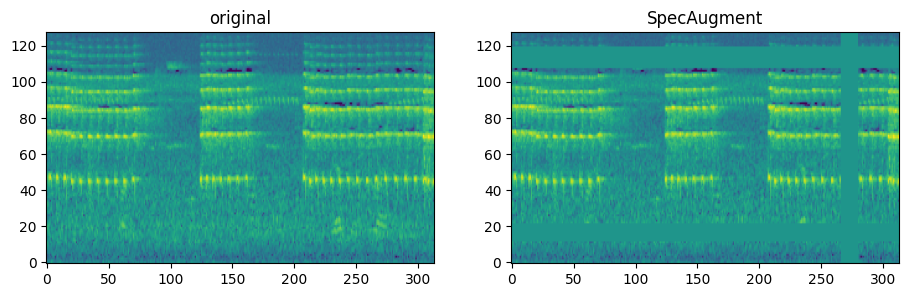

In [28]:
import time, torch, matplotlib.pyplot as plt
from model import make_model
from engine import *
from train_config import *

torch.manual_seed(SEED); np.random.seed(SEED)
train_ds = MelDataset(ALL, rows["train"], Y)
val_ds   = MelDataset(ALL, rows["val"], Y)

# 1) loader speed
tl = make_loader(train_ds, True, w)
t0 = time.time()
for i, (x, y, _) in enumerate(tl):
    if i == 50: break
print(f"loader: {50 * BATCH / (time.time() - t0):.0f} samples/s (includes worker start-up)")

# 2) one GPU training step
model = make_model().to(DEV)
print("parameters (M):", round(sum(p.numel() for p in model.parameters()) / 1e6, 2))
xb = prep(x.to(DEV)); yb = y.to(DEV)
torch.cuda.synchronize(); t0 = time.time()
for _ in range(5):
    with torch.autocast("cuda", dtype=torch.float16):
        loss = nn.BCEWithLogitsLoss()(model(spec_augment(xb)).float(), yb)
    loss.backward()
torch.cuda.synchronize()
print(f"GPU: {5 * BATCH / (time.time() - t0):.0f} samples/s | loss {loss.item():.3f} | out shape {tuple(model(xb).shape)}")

# 3) what augmentation does
a = spec_augment(prep(x[:1].to(DEV)).clone())
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].imshow(prep(x[:1])[0, 0], origin="lower", aspect="auto"); ax[0].set_title("original")
ax[1].imshow(a[0, 0].cpu(), origin="lower", aspect="auto");      ax[1].set_title("SpecAugment")
plt.show()

In [29]:
CK = "/content/drive/MyDrive/birdclef_project/checkpoints"
os.makedirs(CK, exist_ok=True)

torch.manual_seed(SEED); np.random.seed(SEED)
model = make_model().to(DEV)
hist = fit(model, train_ds, val_ds, Y, w, epochs=EPOCHS, ckpt_dir=CK, tag="baseline")
pd.DataFrame(hist).to_csv("results/baseline_history.csv", index=False)

ep 1/10 | loss 0.1107 | val macro-AUC 0.8382 (182 cls) | 108s
ep 2/10 | loss 0.0418 | val macro-AUC 0.9137 (182 cls) | 106s
ep 3/10 | loss 0.0357 | val macro-AUC 0.9468 (182 cls) | 105s
ep 4/10 | loss 0.0328 | val macro-AUC 0.9513 (182 cls) | 105s
ep 5/10 | loss 0.0297 | val macro-AUC 0.9544 (182 cls) | 105s
ep 6/10 | loss 0.0268 | val macro-AUC 0.9590 (182 cls) | 105s
ep 7/10 | loss 0.0264 | val macro-AUC 0.9611 (182 cls) | 106s
ep 8/10 | loss 0.0229 | val macro-AUC 0.9613 (182 cls) | 105s
ep 9/10 | loss 0.0229 | val macro-AUC 0.9601 (182 cls) | 105s
ep 10/10 | loss 0.0222 | val macro-AUC 0.9627 (182 cls) | 109s


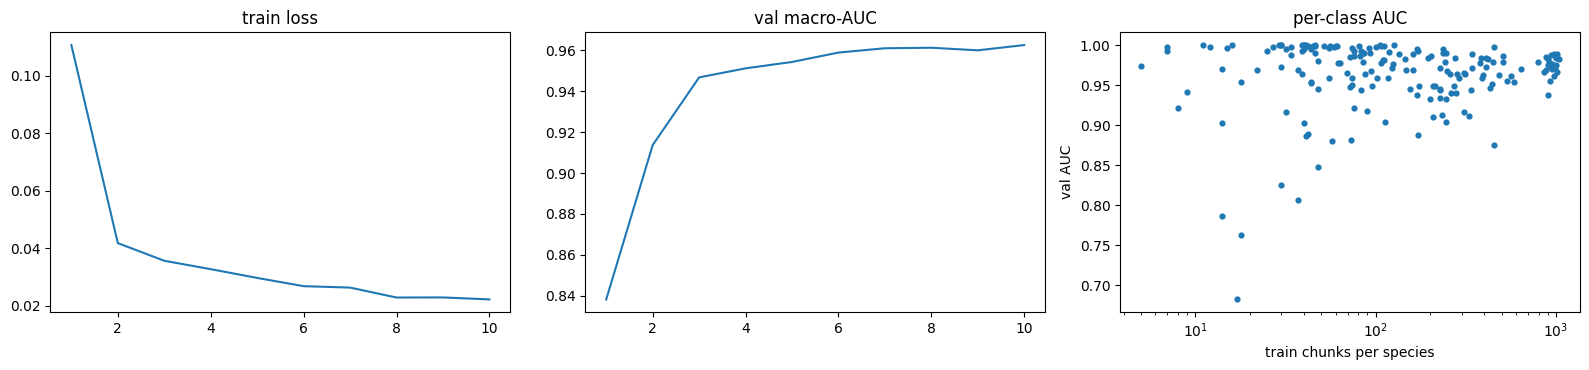

species  val_auc  n_train
pomgrp2 0.682080       17
inpher1 0.762875       18
wbbfly1 0.785772       14
plaflo1 0.805784       37
brfowl1 0.824997       30
aspswi1 0.847257       48
 commyn 0.875324      451
yebbab1 0.880550       57
orihob2 0.881387       73
lobsun2 0.886756       41


In [30]:
from metrics import per_class_auc

h = pd.DataFrame(hist)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].plot(h.epoch + 1, h.loss); ax[0].set_title("train loss")
ax[1].plot(h.epoch + 1, h.val_auc); ax[1].set_title("val macro-AUC")

model.load_state_dict(torch.load(f"{CK}/baseline_best.pt", map_location=DEV))
Pv = predict(model, make_loader(val_ds, False))
a = per_class_auc(Y[rows["val"]], Pv)
n_train = pd.Series(idx.primary_label.values[rows["train"]]).value_counts().reindex(CLASSES).values
ax[2].scatter(n_train, a, s=12); ax[2].set_xscale("log")
ax[2].set_xlabel("train chunks per species"); ax[2].set_ylabel("val AUC"); ax[2].set_title("per-class AUC")
plt.tight_layout(); plt.savefig("results/baseline_curves.png", dpi=120); plt.show()

worst = pd.DataFrame({"species": CLASSES, "val_auc": a, "n_train": n_train}).sort_values("val_auc").head(10)
print(worst.to_string(index=False))

In [31]:
test_ds = MelDataset(ALL, rows["test"], Y)
Pt = predict(model, make_loader(test_ds, False))
test_auc, k = macro_auc(Y[rows["test"]], Pt)
val_auc, _ = macro_auc(Y[rows["val"]], Pv)
print(f"val macro-AUC {val_auc:.4f} | test macro-AUC {test_auc:.4f} ({k} classes)")

import time as _t
json.dump(dict(val_auc=val_auc, test_auc=test_auc, params_M=round(sum(p.numel() for p in model.parameters()) / 1e6, 2),
               epochs=EPOCHS, backbone=BACKBONE if "BACKBONE" in globals() else "efficientnet_b0"),
          open("results/baseline_metrics.json", "w"), indent=2)

val macro-AUC 0.9627 | test macro-AUC 0.9653 (182 classes)


In [ ]:
!ls "/content/drive/MyDrive/Colab Notebooks"
!cp "/content/drive/MyDrive/Colab Notebooks/03_baseline.ipynb" notebooks/
!git add -A
!git status --short
!git commit -m "Phase 3: baseline EfficientNet-B0, training engine, results"
!git push